
# Exploratory Data Analysis on Retail Sales

## Internship
Oasis Infobyte Data Analytics Internship

## Project Objective
The objective of this project is to explore retail sales data, understand sales trends, compare product categories, analyse customer demographics, and identify useful business insights.

## Tools Used
- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn

## Dataset
Retail Sales Dataset downloaded from Kaggle.

In [1]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:


uploaded = files.upload()

csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]

if not csv_files:
    raise ValueError("Please upload a CSV file.")

file_name = csv_files[0]
print("Uploaded file:", file_name)

Saving retail_sales_dataset.csv to retail_sales_dataset.csv
Uploaded file: retail_sales_dataset.csv


In [3]:


df = pd.read_csv(file_name)

print("First five rows:")
display(df.head())

print("\nDataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

First five rows:


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100



Dataset shape: (1000, 9)

Column names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Data types:
Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    

In [4]:


print("Missing values in each column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nNumerical summary:")
display(df.describe())

print("\nCategorical summary:")
display(df.describe(include="object"))

Missing values in each column:


,Missing Values
Transaction ID,0
Date,0
Customer ID,0
Gender,0
Age,0
Product Category,0
Quantity,0
Price per Unit,0
Total Amount,0


Total missing values: 0
Duplicate rows: 0

Numerical summary:


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000



Categorical summary:


,Date,Customer ID,Gender,Product Category
count,1000,1000,1000,1000
unique,345,1000,2,3
top,2023-05-16,CUST1000,Female,Clothing
freq,11,1,510,351


In [5]:


df.columns = df.columns.str.strip()

required_columns = [
    "Transaction ID", "Date", "Customer ID", "Gender",
    "Age", "Product Category", "Quantity",
    "Price per Unit", "Total Amount"
]

missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

df = df.drop_duplicates().copy()

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

numeric_columns = [
    "Transaction ID", "Age", "Quantity",
    "Price per Unit", "Total Amount"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

for col in ["Customer ID", "Gender", "Product Category"]:
    df[col] = df[col].astype("string").str.strip()

print("Missing values after type conversion:")
display(df.isnull().sum().to_frame("Missing Values"))

print("Invalid dates:", df["Date"].isna().sum())
print("Invalid ages:", ((df["Age"] < 0) | (df["Age"] > 120)).sum())
print("Invalid quantities:", (df["Quantity"] <= 0).sum())
print("Invalid prices:", (df["Price per Unit"] < 0).sum())
print("Invalid total amounts:", (df["Total Amount"] < 0).sum())

print("\nCleaning checks completed.")

Missing values after type conversion:


,Missing Values
Transaction ID,0
Date,0
Customer ID,0
Gender,0
Age,0
Product Category,0
Quantity,0
Price per Unit,0
Total Amount,0


Invalid dates: 0
Invalid ages: 0
Invalid quantities: 0
Invalid prices: 0
Invalid total amounts: 0

Cleaning checks completed.


In [6]:


# Remove records that cannot be used for date-based or sales analysis.
df = df.dropna(subset=[
    "Date", "Customer ID", "Gender", "Product Category",
    "Age", "Quantity", "Price per Unit", "Total Amount"
]).copy()

# Keep plausible ages and valid positive quantities and prices.
df = df[
    (df["Age"] >= 0) &
    (df["Age"] <= 120) &
    (df["Quantity"] > 0) &
    (df["Price per Unit"] >= 0) &
    (df["Total Amount"] >= 0)
].copy()

# Check whether the supplied total equals quantity multiplied by unit price.
df["Calculated Amount"] = df["Quantity"] * df["Price per Unit"]

df["Amount Check"] = np.isclose(
    df["Total Amount"],
    df["Calculated Amount"]
)

print("Records remaining after validation:", len(df))
print("Rows with matching amounts:", df["Amount Check"].sum())
print("Rows with mismatched amounts:", (~df["Amount Check"]).sum())

display(df.head())

Records remaining after validation: 1000
Rows with matching amounts: 1000
Rows with mismatched amounts: 0


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount,Calculated Amount,Amount Check
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150,150,True
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000,1000,True
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30,30,True
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500,500,True
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100,100,True


In [7]:


numeric_data = df[
    ["Age", "Quantity", "Price per Unit", "Total Amount"]
]

statistics = pd.DataFrame({
    "Mean": numeric_data.mean(),
    "Median": numeric_data.median(),
    "Mode": numeric_data.mode().iloc[0],
    "Standard Deviation": numeric_data.std(),
    "Minimum": numeric_data.min(),
    "Maximum": numeric_data.max()
})

display(statistics.round(2))

,Mean,Median,Mode,Standard Deviation,Minimum,Maximum
Age,41.39,42.0,43.0,13.68,18,64
Quantity,2.51,3.0,4.0,1.13,1,4
Price per Unit,179.89,50.0,50.0,189.68,25,500
Total Amount,456.00,135.0,50.0,560.00,25,2000


In [8]:


df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Month Name"] = df["Date"].dt.strftime("%b")
df["Month Start"] = df["Date"].dt.to_period("M").dt.to_timestamp()
df["Quarter"] = df["Date"].dt.to_period("Q").astype(str)

monthly_sales = (
    df.groupby("Month Start", as_index=False)["Total Amount"]
    .sum()
    .sort_values("Month Start")
)

quarterly_sales = (
    df.groupby("Quarter", as_index=False)["Total Amount"]
    .sum()
    .sort_values("Quarter")
)

print("Monthly sales:")
display(monthly_sales)

print("Quarterly sales:")
display(quarterly_sales)

Monthly sales:


,Month Start,Total Amount
0,2023-01-01,35450
1,2023-02-01,44060
2,2023-03-01,28990
3,2023-04-01,33870
4,2023-05-01,53150
5,2023-06-01,36715
6,2023-07-01,35465
7,2023-08-01,36960
8,2023-09-01,23620
9,2023-10-01,46580


Quarterly sales:


,Quarter,Total Amount
0,2023Q1,108500
1,2023Q2,123735
2,2023Q3,96045
3,2023Q4,126190
4,2024Q1,1530


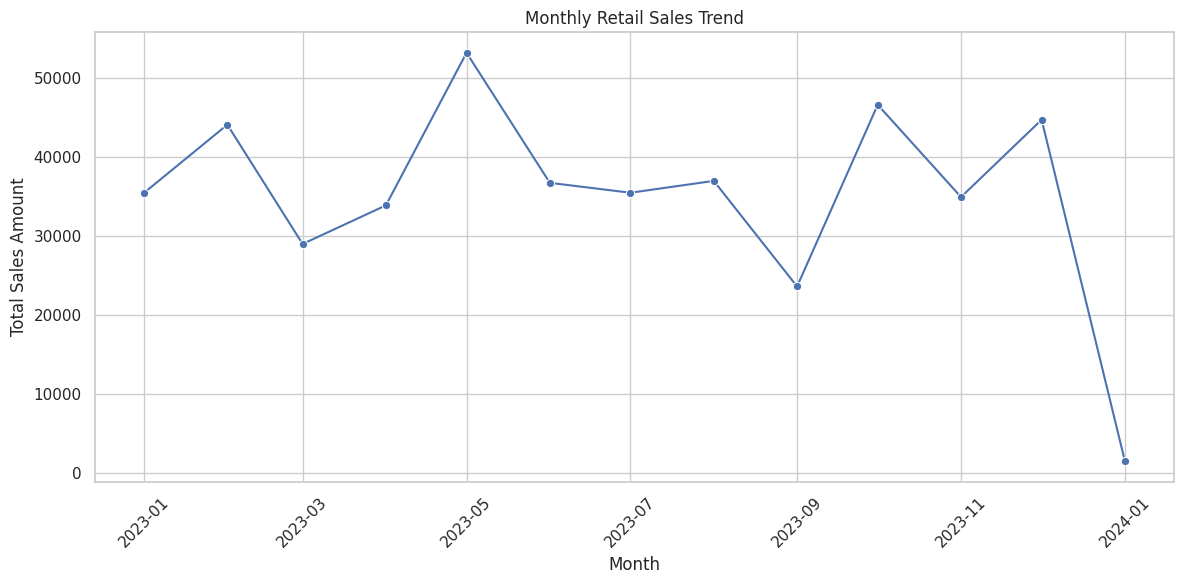

Highest-sales month: May 2023, sales = 53,150.00


In [9]:


plt.figure(figsize=(12, 6))
sns.lineplot(
    data=monthly_sales,
    x="Month Start",
    y="Total Amount",
    marker="o"
)

plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

if not monthly_sales.empty:
    best_month = monthly_sales.loc[
        monthly_sales["Total Amount"].idxmax()
    ]
    print(
        f"Highest-sales month: {best_month['Month Start']:%B %Y}, "
        f"sales = {best_month['Total Amount']:,.2f}"
    )

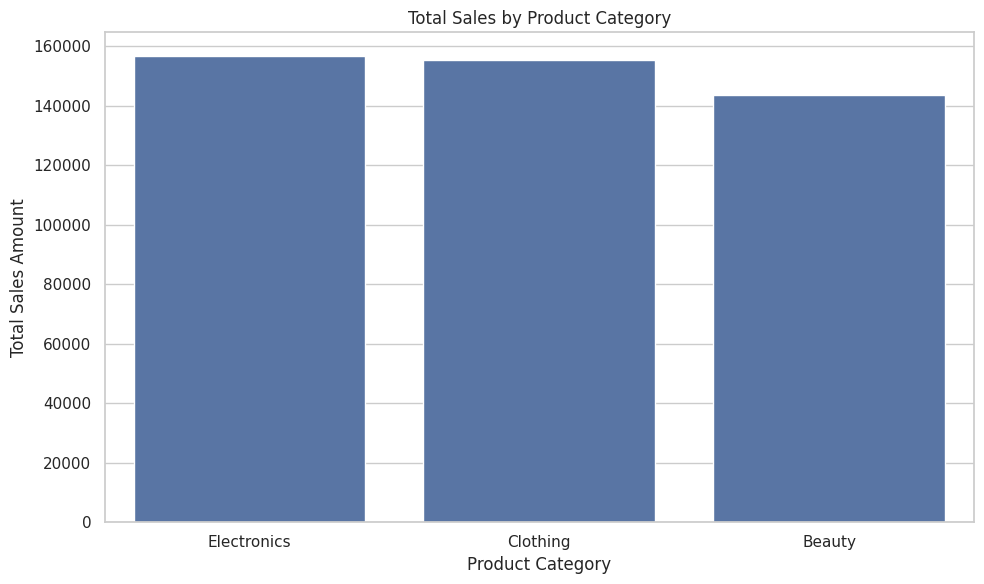

,Product Category,Total_Sales,Units_Sold,Transactions
2,Electronics,156905,849,342
1,Clothing,155580,894,351
0,Beauty,143515,771,307


In [10]:


category_sales = (
    df.groupby("Product Category", as_index=False)
    .agg(
        Total_Sales=("Total Amount", "sum"),
        Units_Sold=("Quantity", "sum"),
        Transactions=("Transaction ID", "count")
    )
    .sort_values("Total_Sales", ascending=False)
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=category_sales,
    x="Product Category",
    y="Total_Sales"
)

plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales Amount")
plt.tight_layout()
plt.show()

display(category_sales)

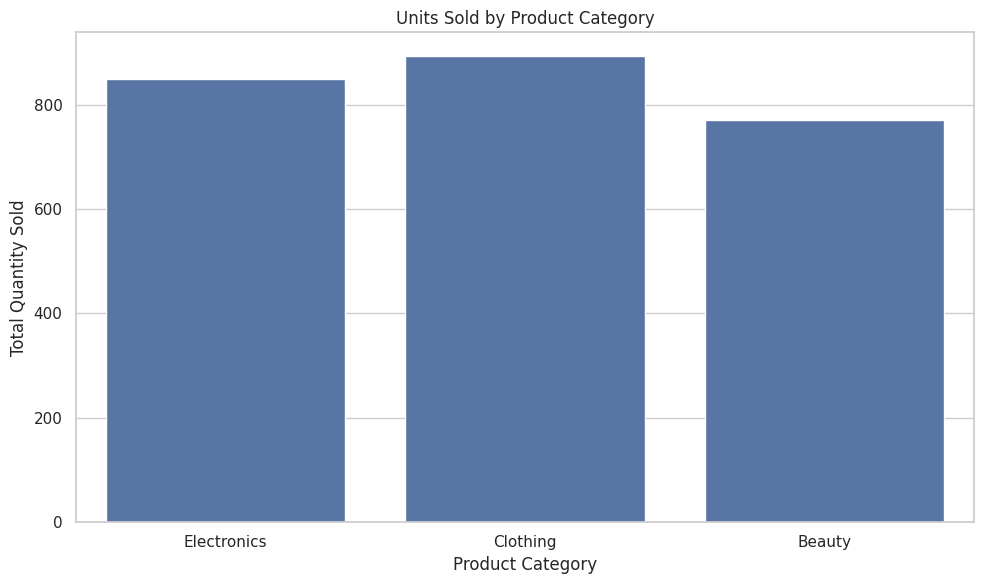

In [11]:


plt.figure(figsize=(10, 6))
sns.barplot(
    data=category_sales,
    x="Product Category",
    y="Units_Sold"
)

plt.title("Units Sold by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Quantity Sold")
plt.tight_layout()
plt.show()

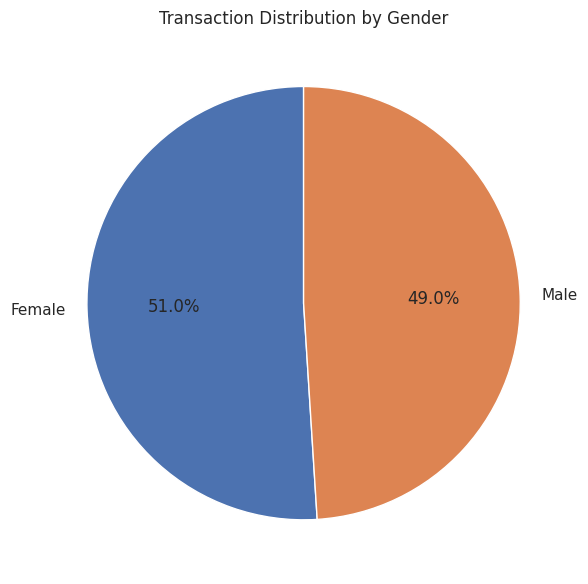

,Gender,Transactions
0,Female,510
1,Male,490


In [12]:


gender_counts = df["Gender"].value_counts().reset_index()
gender_counts.columns = ["Gender", "Transactions"]

plt.figure(figsize=(8, 6))
plt.pie(
    gender_counts["Transactions"],
    labels=gender_counts["Gender"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Transaction Distribution by Gender")
plt.tight_layout()
plt.show()

display(gender_counts)

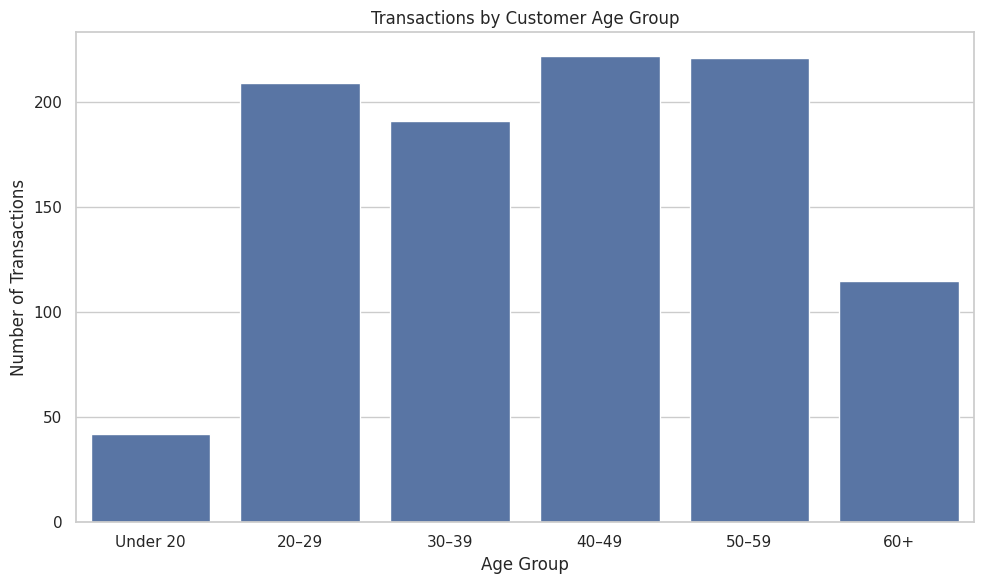

,Age Group,Transactions,Total_Sales
0,Under 20,42,26085
1,20–29,209,97070
2,30–39,191,96325
3,40–49,222,93365
4,50–59,221,98340
5,60+,115,44815


In [13]:


bins = [0, 19, 29, 39, 49, 59, 120]
labels = ["Under 20", "20–29", "30–39", "40–49", "50–59", "60+"]

df["Age Group"] = pd.cut(
    df["Age"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

age_group_sales = (
    df.groupby("Age Group", observed=False, as_index=False)
    .agg(
        Transactions=("Transaction ID", "count"),
        Total_Sales=("Total Amount", "sum")
    )
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=age_group_sales,
    x="Age Group",
    y="Transactions"
)

plt.title("Transactions by Customer Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

display(age_group_sales)

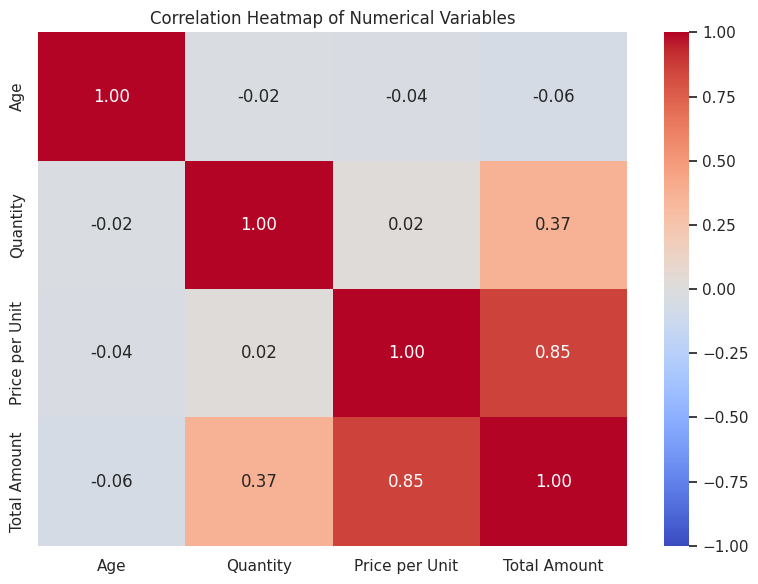

In [14]:


correlation_columns = [
    "Age", "Quantity", "Price per Unit", "Total Amount"
]

correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

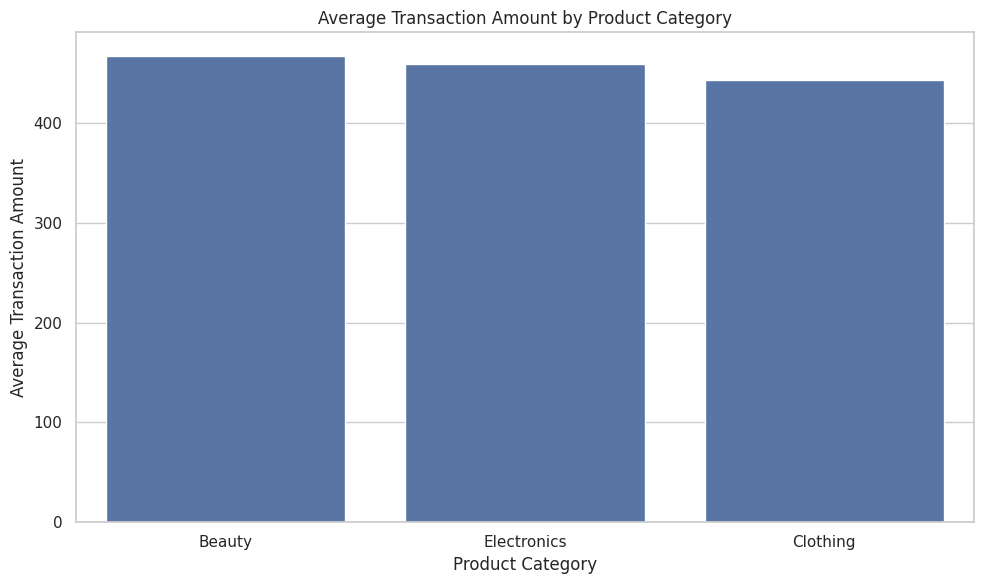

,Product Category,Average_Transaction
0,Beauty,467.48
2,Electronics,458.79
1,Clothing,443.25


In [15]:


average_transaction = (
    df.groupby("Product Category", as_index=False)
    .agg(Average_Transaction=("Total Amount", "mean"))
    .sort_values("Average_Transaction", ascending=False)
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=average_transaction,
    x="Product Category",
    y="Average_Transaction"
)

plt.title("Average Transaction Amount by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Transaction Amount")
plt.tight_layout()
plt.show()

display(average_transaction.round(2))

In [16]:


total_sales = df["Total Amount"].sum()
total_transactions = len(df)
average_transaction_amount = df["Total Amount"].mean()

best_category = category_sales.iloc[0]
highest_month = monthly_sales.loc[
    monthly_sales["Total Amount"].idxmax()
]
largest_age_group = age_group_sales.loc[
    age_group_sales["Transactions"].idxmax()
]
largest_gender_group = gender_counts.loc[
    gender_counts["Transactions"].idxmax()
]

print("KEY BUSINESS FINDINGS")
print("-" * 40)
print(f"Total sales amount: {total_sales:,.2f}")
print(f"Number of transactions: {total_transactions:,}")
print(f"Average transaction amount: {average_transaction_amount:,.2f}")
print(
    f"Highest-sales category: {best_category['Product Category']} "
    f"({best_category['Total_Sales']:,.2f})"
)
print(
    f"Highest-sales month: {highest_month['Month Start']:%B %Y} "
    f"({highest_month['Total Amount']:,.2f})"
)
print(
    f"Largest age group by transactions: "
    f"{largest_age_group['Age Group']}"
)
print(
    f"Gender with more transactions: "
    f"{largest_gender_group['Gender']}"
)

KEY BUSINESS FINDINGS
----------------------------------------
Total sales amount: 456,000.00
Number of transactions: 1,000
Average transaction amount: 456.00
Highest-sales category: Electronics (156,905.00)
Highest-sales month: May 2023 (53,150.00)
Largest age group by transactions: 40–49
Gender with more transactions: Female



## Business Recommendations

1. **Category strategy:** Review the sales and quantity charts to identify categories that generate the most revenue and units sold. Plan inventory and promotions accordingly.

2. **Customer engagement:** Use the age-group and gender analysis to understand who is making purchases. Validate these patterns with additional data before targeting customer groups.

3. **Sales planning:** Use monthly and quarterly sales trends to support inventory and promotional planning. A longer historical dataset would be needed to establish reliable seasonal patterns.

4. **Data quality:** Investigate invalid dates, missing values, duplicate records, and mismatches between quantity, unit price, and total amount before using the results for business decisions.

5. **Further analysis:** Collect individual product names and costs to analyse best-selling products, profit margins, and product-level performance.


## Conclusion

This project explored retail sales data using Python, Pandas, Matplotlib, and Seaborn. It examined data quality, descriptive statistics, monthly and quarterly sales trends, product-category performance, customer demographics, and relationships between numerical variables.

The results can help support sales planning and customer analysis. The findings should be interpreted within the limits of the available dataset. In particular, product-level rankings and profitability cannot be calculated without product names and cost information.

In [17]:


output_file = "cleaned_retail_sales.csv"

export_columns = [
    "Transaction ID", "Date", "Customer ID", "Gender",
    "Age", "Age Group", "Product Category", "Quantity",
    "Price per Unit", "Total Amount", "Year", "Month",
    "Quarter"
]

df[export_columns].to_csv(output_file, index=False)

print("Cleaned dataset saved as:", output_file)
files.download(output_file)

Cleaned dataset saved as: cleaned_retail_sales.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>